# SO LAT RM reconstruction noise
Six bands with atmospheric noise and cross-band covariances, following the linked COBI configuration. Full-sky isotropic forecast: fsky controls survey depth only. No foreground cleaning, foreground residuals, mask, or cut-sky filtering is modeled.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from rm_noise import (PRISM, REFERENCE, camb_spectra, white_instrument,
                      so_lat_instrument, Geometry, reconstruction_noise, noise_dl, pmf_dl)
OUTPUT = Path('outputs')
OUTPUT.mkdir(exist_ok=True)

In [2]:
LMAX_CMB, LMAX_RM = 5000, 100
FSKY, SENSITIVITY = 0.4, "baseline"
USE_TB = True
RESIDUALS = [1., 0.5, 0.14, 0.]

## Instrument and CMB
`so_lat_instrument` calls the public SO model using 5 years, efficiency 0.2 and tube counts [1.8, 12, 6]. EB-only uses its polarization covariance; EB+TB additionally uses temperature covariance from the same model.

In [3]:
instrument = so_lat_instrument(LMAX_CMB, FSKY, SENSITIVITY)
print("Bands GHz:", instrument[0])
prim, lensed = camb_spectra(LMAX_CMB)
geo = Geometry(LMAX_CMB, LMAX_RM)

Bands GHz: [ 27.  39.  93. 145. 225. 280.]


## Noise curves
Eqs. (7–12): joint frequency and T/E covariance weighting followed by the angular sum. Each fraction interpolates all four sky spectra between unlensed and lensed values.

In [4]:
L = np.arange(1, LMAX_RM+1)
curves = {f: noise_dl(reconstruction_noise(geo, prim, lensed, instrument, f, USE_TB))[1:]
          for f in RESIDUALS}
for f, y in curves.items():
    print(f, 'D at L=1,10,30,100:', y[np.array([1,10,30,100])-1])

1.0 D at L=1,10,30,100: [6.65257348e+01 3.66107433e+03 3.10895127e+04 3.52964069e+05]
0.5 D at L=1,10,30,100: [6.47891197e+01 3.56550706e+03 3.02781920e+04 3.43814444e+05]
0.14 D at L=1,10,30,100: [6.33334939e+01 3.48540102e+03 2.95980130e+04 3.36129959e+05]
0.0 D at L=1,10,30,100: [6.27167847e+01 3.45146189e+03 2.93098124e+04 3.32871063e+05]


In [5]:
gal_L = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 56, 61, 66, 71, 76, 81, 86, 91, 96])
gal_D = np.array([462.34916, 104.96586, 277.57711, 51.115451, 297.63591, 92.494455, 336.30572, 118.59652, 243.53861, 110.12486, 184.22783, 117.56593, 218.38252, 152.72553, 223.19387, 118.08331, 209.06802, 204.54938, 147.49316, 165.92518, 209.06802, 139.97521, 179.46667, 172.56754, 171.81144, 150.7432, 222.22877, 188.28733, 177.13665, 209.97668, 193.28315, 165.19819, 114.52719, 161.63649, 121.74324, 133.41782, 143.05911, 125.5166, 134.58738, 122.81086, 113.04066, 89.714126, 105.886, 87.017078, 104.05372, 104.96586, 110.60348, 78.712736, 93.305269, 118.08331, 103.60308, 66.402186, 61.388745, 59.025808, 70.582177, 59.282347, 60.855282, 54.809438, 51.337523])

## Figure and exported curves
Includes the scale-invariant 1 nG level; Galactic RM is a reference curve only.

f_DL=1: largest L with 1 nG signal above noise = 8
f_DL=0.5: largest L with 1 nG signal above noise = 8
f_DL=0.14: largest L with 1 nG signal above noise = 8
f_DL=0: largest L with 1 nG signal above noise = 8


<ipython-input-1-e3ba0b1f6f3f>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


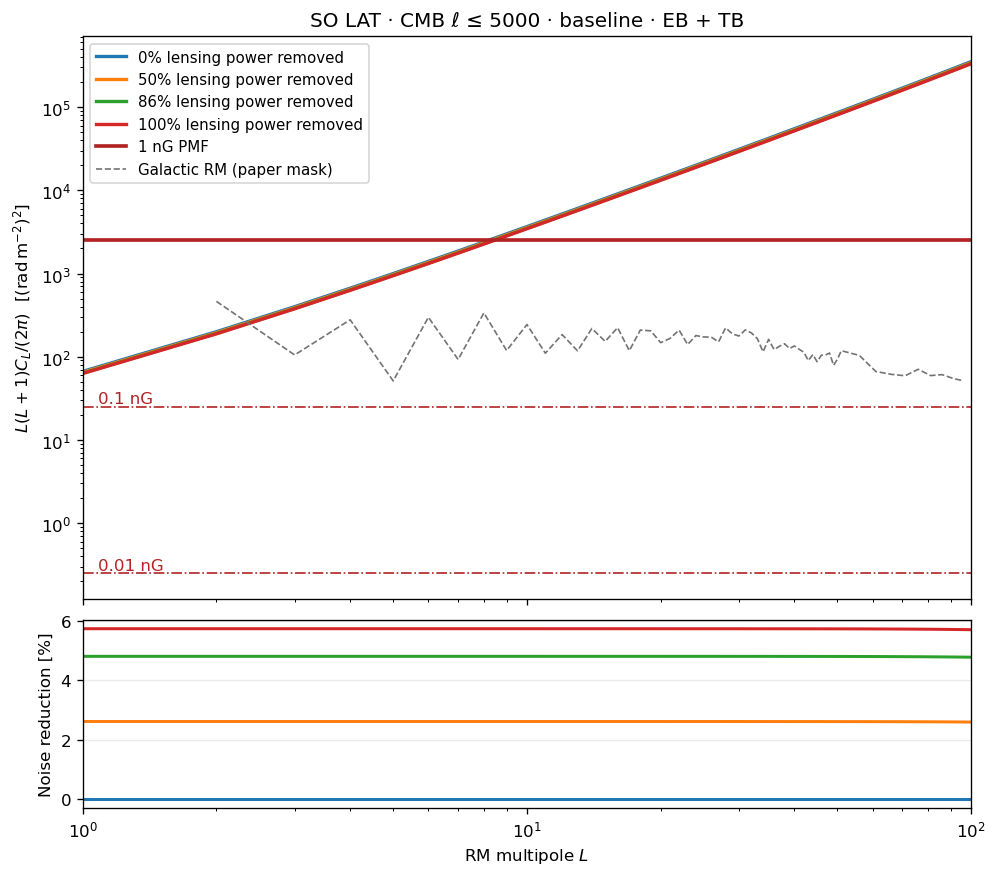

In [6]:
fig, (ax, ratio) = plt.subplots(2, 1, sharex=True, figsize=(8.2, 7.2),
                                height_ratios=[3, 1], layout="constrained")
undelensed = curves[1.] if 1. in curves else noise_dl(reconstruction_noise(geo, prim, lensed, instrument, 1., USE_TB))[1:]
for f, y in curves.items():
    ratio.semilogx(L, 100*(1-y/undelensed), lw=1.8)
    ax.loglog(L, y, lw=2, label=f"{100*(1-f):g}% lensing power removed")
field_ng = 1.0
signal = (50 * field_ng)**2
ax.axhline(signal, color="firebrick", lw=2.2, label="1 nG PMF")
for f, noise in curves.items():
    above = L[signal > noise]
    print(f"f_DL={f:g}: largest L with 1 nG signal above noise = {above.max() if above.size else 'none'}")
for field in [0.1,0.01]:
    ax.axhline((50*field)**2, color="firebrick", ls="-.", lw=1)
    ax.text(1.08,(50*field)**2*1.1, f"{field} nG", color="firebrick")
ax.loglog(gal_L,gal_D,"--",color="0.45",lw=1,label="Galactic RM (paper mask)")
ax.set(xlim=(1,LMAX_RM),
       ylabel=r"$L(L+1) C_L/(2\pi)$  $[(\mathrm{rad}\,\mathrm{m}^{-2})^2]$",
       title=f"SO LAT · CMB ℓ ≤ {LMAX_CMB} · {SENSITIVITY} · {'EB + TB' if USE_TB else 'EB only'}")
ax.legend(fontsize=9)
ratio.set(xlabel="RM multipole $L$", ylabel="Noise reduction [%]")
ratio.grid(axis="y", alpha=0.25)
fig.savefig(OUTPUT/'so_lat.png', dpi=180)
plt.show()

In [7]:
np.savetxt(OUTPUT/'so_lat_curves.csv', np.column_stack([L,*curves.values()]), delimiter=',', header=','.join(['L',*[f'f_{f}' for f in curves]]), comments='')